<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Box Plots**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize data composition and comparisons using box plots.


### Setup: Connecting to the Database


#### 1. Download the Database File


In [1]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Saving to: ‘survey-results-public.sqlite’

survey-results-publ 100%[===================>] 201.62M  1.07MB/s    in 75s     
2026-10-15 21:16:22 (2.68 MB/s) - ‘survey-results-public.sqlite’ saved [211415040/211415040]


#### 2. Connect to the Database


**Install the needed libraries**


In [2]:
!pip install pandas

In [3]:
!pip install matplotlib

In [4]:
!pip install seaborn

In [5]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the SQLite database
conn = sqlite3.connect('survey-results-public.sqlite')


## Demo: Basic SQL Queries


#### Demo 1: Count the Number of Rows in the Table


In [6]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)


   COUNT(*)
0     65437

#### Demo 2: List All Tables


In [7]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


#### Demo 3: Group Data by Age


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)


                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568

## Visualizing Data


### Task 1: Visualizing the Distribution of Data


**1. Box Plot of `CompTotal` (Total Compensation)**


Use a box plot to analyze the distribution and outliers in total compensation.


--- Dataset Summary Statistics ---
Median Compensation: $110,000.00
First Quartile (Q1): $60,000.00
Third Quartile (Q3): $250,000.00
Interquartile Range (IQR): $190,000.00
Upper Outlier Threshold (Q3 + 1.5*IQR): $535,000.00

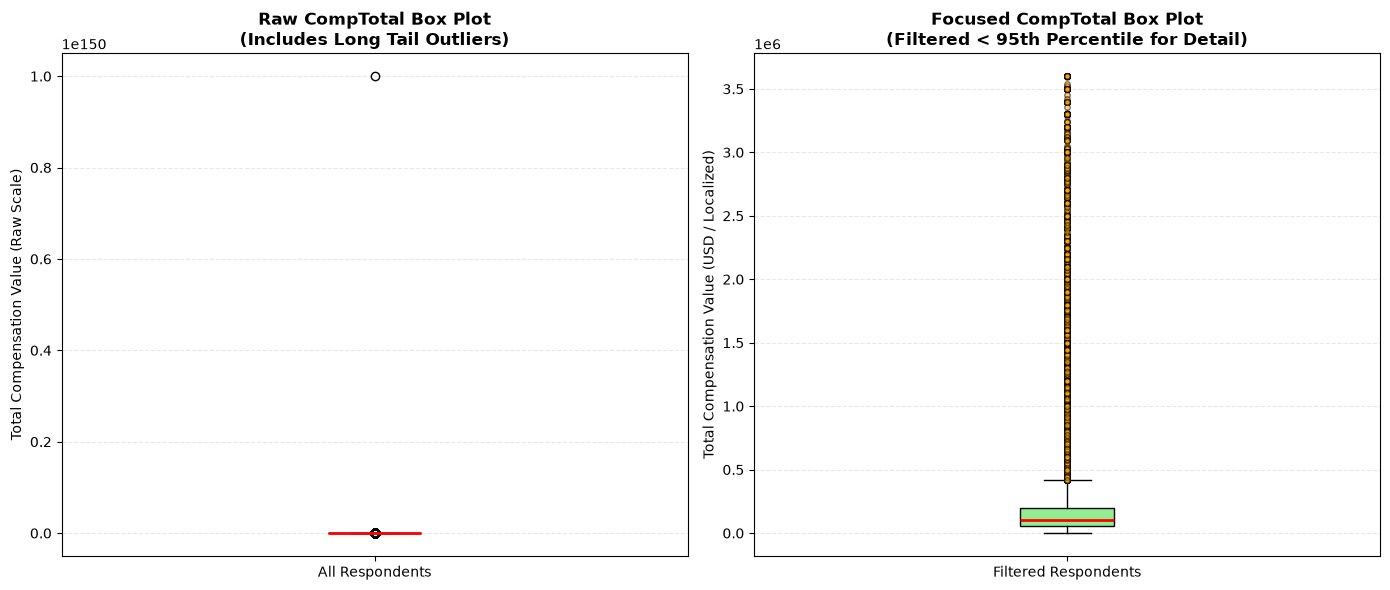

In [9]:
QUERY = """
SELECT CompTotal 
FROM main
WHERE CompTotal IS NOT NULL
"""
df = pd.read_sql_query(QUERY, conn)


median_val = df['CompTotal'].median()
q1 = df['CompTotal'].quantile(0.25)
q3 = df['CompTotal'].quantile(0.75)
iqr = q3 - q1
upper_outlier_bound = q3 + (1.5 * iqr)

print(f"--- Dataset Summary Statistics ---")
print(f"Median Compensation: ${median_val:,.2f}")
print(f"First Quartile (Q1): ${q1:,.2f}")
print(f"Third Quartile (Q3): ${q3:,.2f}")
print(f"Interquartile Range (IQR): ${iqr:,.2f}")
print(f"Upper Outlier Threshold (Q3 + 1.5*IQR): ${upper_outlier_bound:,.2f}")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))


ax1.boxplot(df['CompTotal'], patch_artist=True, 
            boxprops=dict(facecolor='lightblue', color='black'),
            medianprops=dict(color='red', linewidth=2))
ax1.set_title('Raw CompTotal Box Plot\n(Includes Long Tail Outliers)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Compensation Value (Raw Scale)')
ax1.set_xticklabels(['All Respondents'])
ax1.grid(axis='y', linestyle='--', alpha=0.3)


upper_limit = df['CompTotal'].quantile(0.95)
df_filtered = df[df['CompTotal'] <= upper_limit]

ax2.boxplot(df_filtered['CompTotal'], patch_artist=True, 
            boxprops=dict(facecolor='lightgreen', color='black'),
            medianprops=dict(color='red', linewidth=2),
            flierprops=dict(marker='o', markerfacecolor='orange', markersize=4, alpha=0.5))
ax2.set_title('Focused CompTotal Box Plot\n(Filtered < 95th Percentile for Detail)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Total Compensation Value (USD / Localized)')
ax2.set_xticklabels(['Filtered Respondents'])
ax2.grid(axis='y', linestyle='--', alpha=0.3)


plt.tight_layout()
plt.show()



**2. Box Plot of Age (converted to numeric values)**


Convert the `Age` column into numerical values and visualize the distribution.


--- Age Demographic Summary Statistics ---
Median Age: 29.5 years old
First Quartile (Q1): 21.0 years old
Third Quartile (Q3): 39.5 years old
Interquartile Range (IQR): 18.5 years

AttributeError: module 'matplotlib.pyplot' has no attribute 'xticklabels'

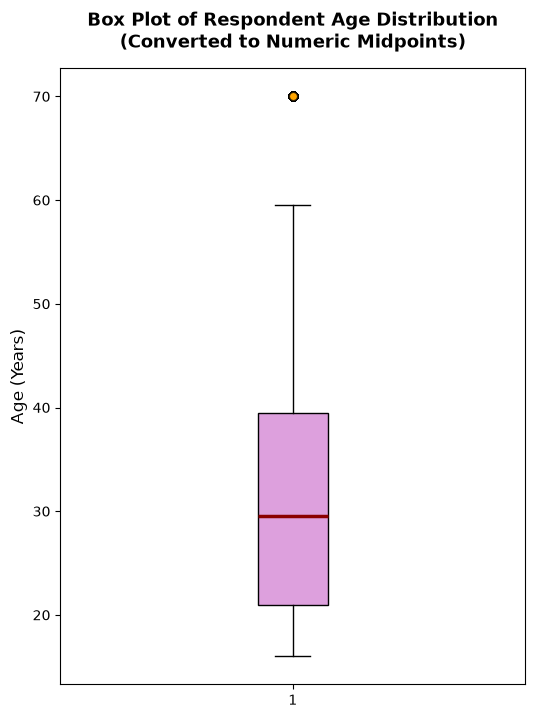

In [10]:

QUERY = """
SELECT Age 
FROM main
WHERE Age IS NOT NULL 
  AND Age != 'Prefer not to say'
"""
df = pd.read_sql_query(QUERY, conn)


age_mapping = {
    'Under 18 years old': 16.0,
    '18-24 years old': 21.0,
    '25-34 years old': 29.5,
    '35-44 years old': 39.5,
    '45-54 years old': 49.5,
    '55-64 years old': 59.5,
    '65 years or older': 70.0
}


df['Age_Numeric'] = df['Age'].map(age_mapping)


df = df.dropna(subset=['Age_Numeric'])


median_age = df['Age_Numeric'].median()
q1_age = df['Age_Numeric'].quantile(0.25)
q3_age = df['Age_Numeric'].quantile(0.75)
iqr_age = q3_age - q1_age

print("--- Age Demographic Summary Statistics ---")
print(f"Median Age: {median_age:.1f} years old")
print(f"First Quartile (Q1): {q1_age:.1f} years old")
print(f"Third Quartile (Q3): {q3_age:.1f} years old")
print(f"Interquartile Range (IQR): {iqr_age:.1f} years")


plt.figure(figsize=(6, 8))

plt.boxplot(df['Age_Numeric'], patch_artist=True,
            boxprops=dict(facecolor='plum', color='black'),
            medianprops=dict(color='darkred', linewidth=2.5),
            flierprops=dict(marker='o', markerfacecolor='orange', markersize=6, alpha=0.6))


plt.title('Box Plot of Respondent Age Distribution\n(Converted to Numeric Midpoints)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Age (Years)', fontsize=12)
plt.xticklabels(['Survey Respondents'])
plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()



### Task 2: Visualizing Relationships in Data


**1. Box Plot of `CompTotal` Grouped by Age Groups:**


Visualize the distribution of compensation across different age groups.


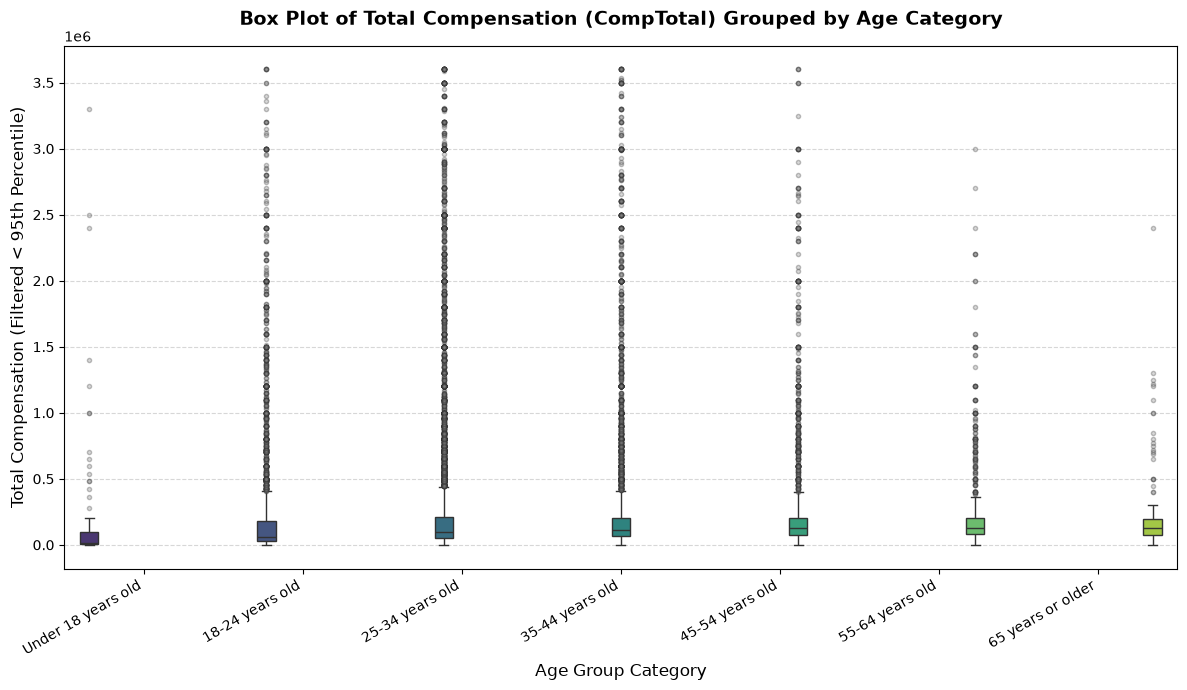

In [11]:
QUERY = """
SELECT CompTotal, Age 
FROM main
WHERE CompTotal IS NOT NULL 
  AND Age IS NOT NULL 
  AND Age != 'Prefer not to say'
"""
df = pd.read_sql_query(QUERY, conn)


upper_limit = df['CompTotal'].quantile(0.95)
df_filtered = df[df['CompTotal'] <= upper_limit]


age_order = [
    'Under 18 years old',
    '18-24 years old',
    '25-34 years old',
    '35-44 years old',
    '45-54 years old',
    '55-64 years old',
    '65 years or older'
]


df_filtered['Age'] = pd.Categorical(df_filtered['Age'], categories=age_order, ordered=True)
df_filtered = df_filtered.dropna(subset=['Age']) 


plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df_filtered,
    x='Age',
    y='CompTotal',
    palette='viridis',
    hue='Age',         
    legend=False,
    flierprops=dict(marker='o', markerfacecolor='grey', markersize=3, alpha=0.3)
)


plt.title('Box Plot of Total Compensation (CompTotal) Grouped by Age Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age Group Category', fontsize=12)
plt.ylabel('Total Compensation (Filtered < 95th Percentile)', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()


**2. Box Plot of `CompTotal` Grouped by Job Satisfaction (`JobSatPoints_6`):**


Examine how compensation varies based on job satisfaction levels.


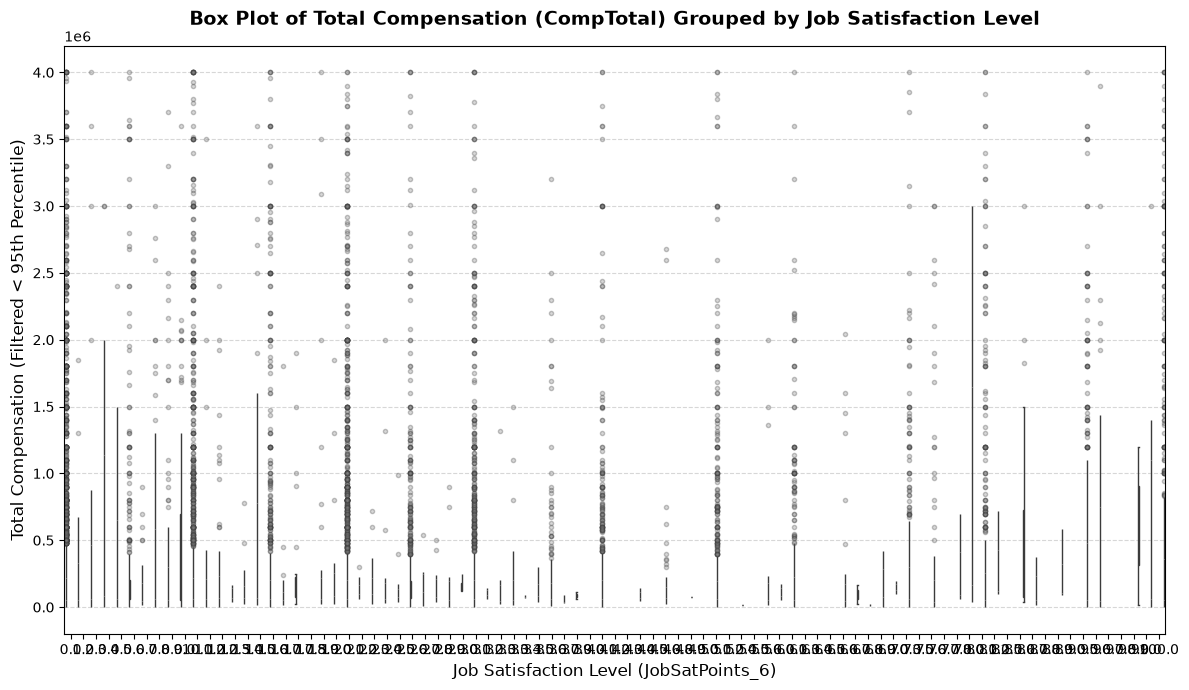

In [12]:
QUERY = """
SELECT CompTotal, JobSatPoints_6 
FROM main
WHERE CompTotal IS NOT NULL 
  AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(QUERY, conn)


upper_limit = df['CompTotal'].quantile(0.95)
df_filtered = df[df['CompTotal'] <= upper_limit]


sat_order = sorted(df_filtered['JobSatPoints_6'].unique())
df_filtered['JobSatPoints_6'] = pd.Categorical(df_filtered['JobSatPoints_6'], categories=sat_order, ordered=True)


plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df_filtered,
    x='JobSatPoints_6',
    y='CompTotal',
    palette='coolwarm',
    hue='JobSatPoints_6',  
    legend=False,
    flierprops=dict(marker='o', markerfacecolor='grey', markersize=3, alpha=0.3)
)


plt.title('Box Plot of Total Compensation (CompTotal) Grouped by Job Satisfaction Level', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Job Satisfaction Level (JobSatPoints_6)', fontsize=12)
plt.ylabel('Total Compensation (Filtered < 95th Percentile)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()


### Task 3: Visualizing the Composition of Data


**1. Box Plot of `ConvertedCompYearly` for the Top 5 Developer Types:**


Analyze compensation across the top 5 developer roles.


Top 5 Developer Roles detected: ['Developer, full-stack', 'Developer, back-end', 'Developer, front-end', 'Developer, desktop or enterprise applications', 'Developer, mobile']

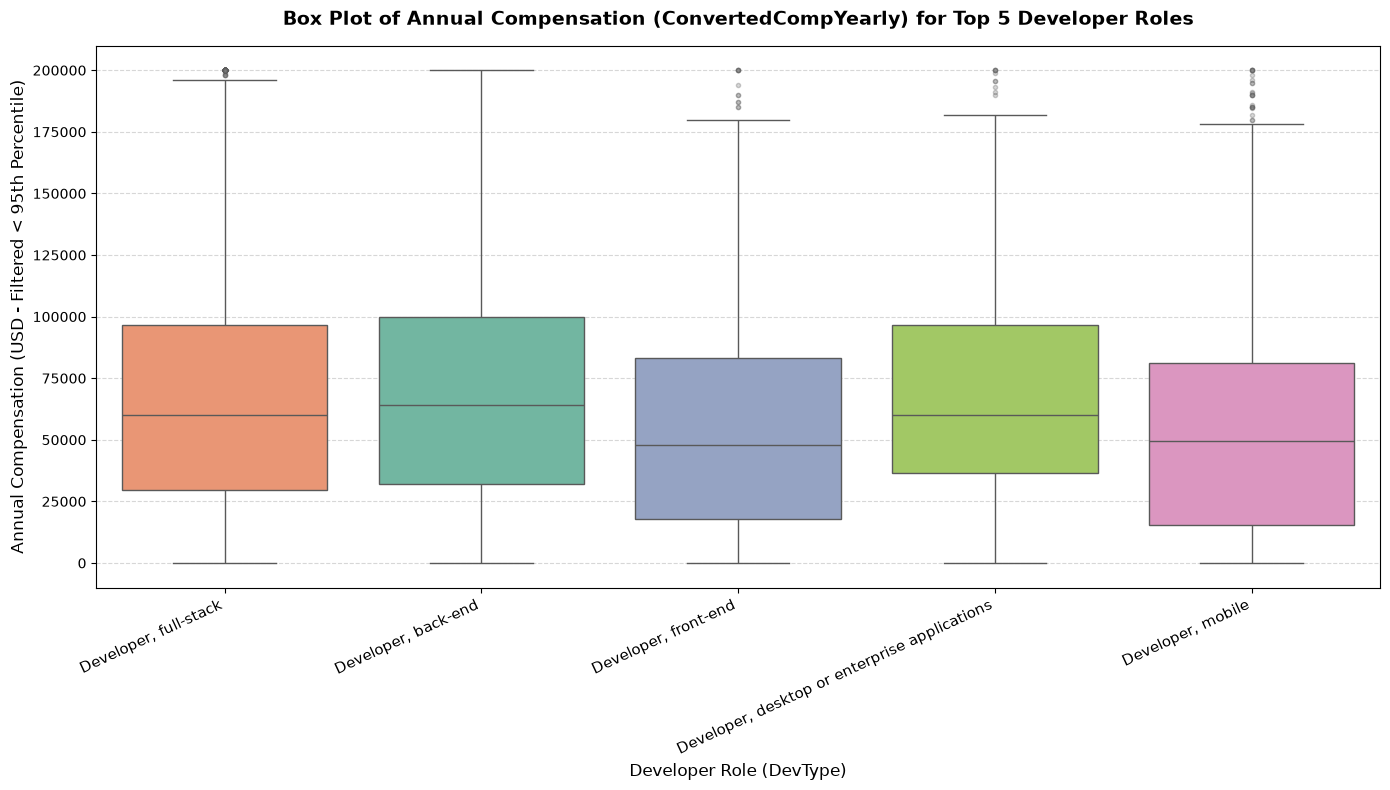

In [13]:
QUERY = """
SELECT ConvertedCompYearly, DevType 
FROM main
WHERE ConvertedCompYearly IS NOT NULL 
  AND DevType IS NOT NULL 
  AND DevType != ''
"""
df_raw = pd.read_sql_query(QUERY, conn)


df_raw['DevType'] = df_raw['DevType'].str.split(';')
df_exploded = df_raw.explode('DevType')


top_5_roles = df_exploded['DevType'].value_counts().head(5).index.tolist()
print(f"Top 5 Developer Roles detected: {top_5_roles}")


df_top5 = df_exploded[df_exploded['DevType'].isin(top_5_roles)]


upper_limit = df_top5['ConvertedCompYearly'].quantile(0.95)
df_filtered = df_top5[df_top5['ConvertedCompYearly'] <= upper_limit]


plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df_filtered,
    x='DevType',
    y='ConvertedCompYearly',
    order=top_5_roles,      
    palette='Set2',
    hue='DevType',          
    legend=False,
    flierprops=dict(marker='o', markerfacecolor='grey', markersize=3, alpha=0.3)
)


plt.title('Box Plot of Annual Compensation (ConvertedCompYearly) for Top 5 Developer Roles', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Developer Role (DevType)', fontsize=12)
plt.ylabel('Annual Compensation (USD - Filtered < 95th Percentile)', fontsize=12)
plt.xticks(rotation=25, ha='right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()


**2. Box Plot of `CompTotal` for the Top 5 Countries:**


Analyze compensation across respondents from the top 5 countries.


Top 5 Countries detected: ['United States of America', 'Germany', 'United Kingdom of Great Britain and Northern Ireland', 'Ukraine', 'India']

Median CompTotal for United States of America: 147,000.00 (Local Currency)
Median CompTotal for Germany: 69,000.00 (Local Currency)
Median CompTotal for United Kingdom of Great Britain and Northern Ireland: 67,000.00 (Local Currency)
Median CompTotal for Ukraine: 66,000.00 (Local Currency)
Median CompTotal for India: 1,300,000.00 (Local Currency)

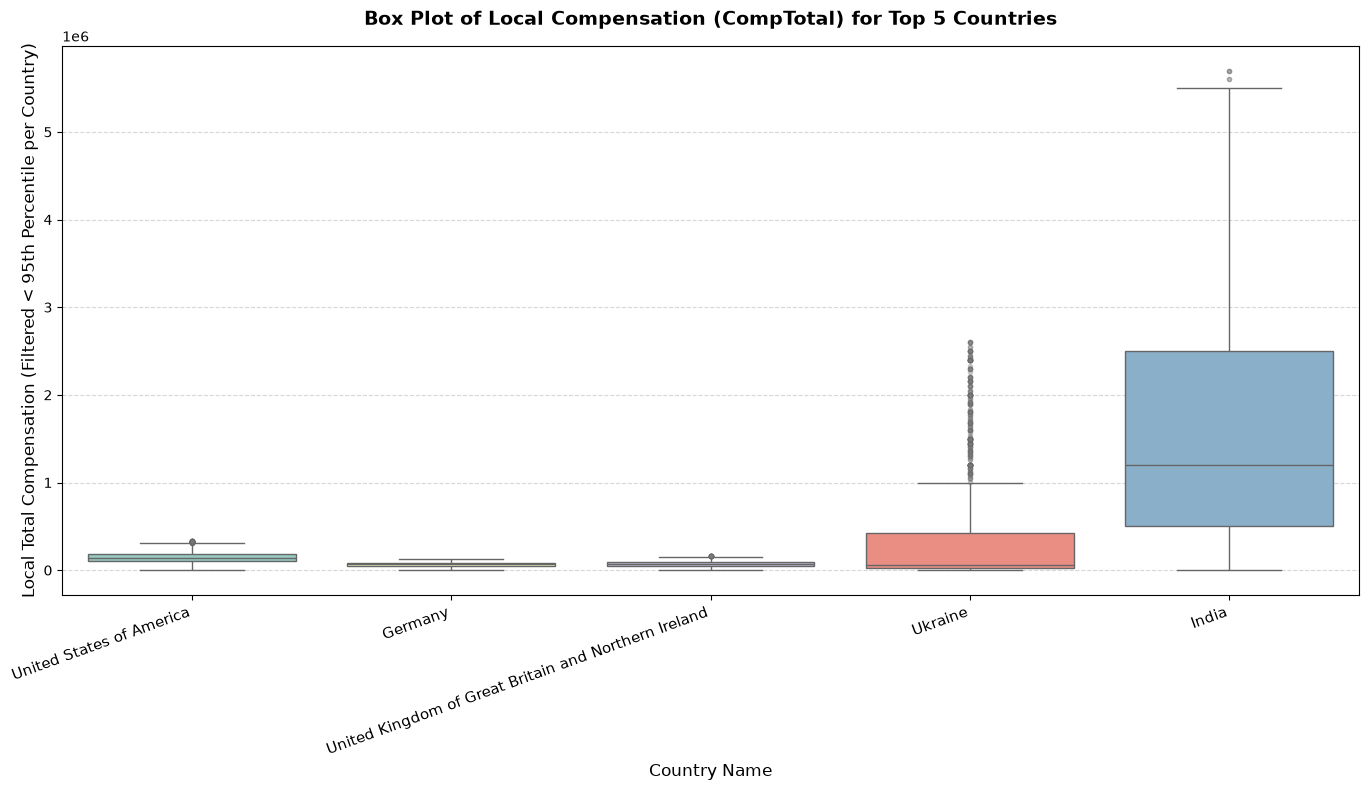

In [14]:
QUERY = """
SELECT CompTotal, Country 
FROM main
WHERE CompTotal IS NOT NULL 
  AND Country IS NOT NULL 
  AND Country != ''
"""
df_raw = pd.read_sql_query(QUERY, conn)


top_5_countries = df_raw['Country'].value_counts().head(5).index.tolist()
print(f"Top 5 Countries detected: {top_5_countries}\n")


df_top5 = df_raw[df_raw['Country'].isin(top_5_countries)].copy()


filtered_list = []
for country in top_5_countries:
    country_subset = df_top5[df_top5['Country'] == country]
    
    
    local_upper_limit = country_subset['CompTotal'].quantile(0.95)
    country_filtered = country_subset[country_subset['CompTotal'] <= local_upper_limit]
    filtered_list.append(country_filtered)
    
    
    local_median = country_subset['CompTotal'].median()
    print(f"Median CompTotal for {country}: {local_median:,.2f} (Local Currency)")


df_final = pd.concat(filtered_list, ignore_index=True)


plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df_final,
    x='Country',
    y='CompTotal',
    order=top_5_countries,   
    palette='Set3',
    hue='Country',           
    legend=False,
    flierprops=dict(marker='o', markerfacecolor='grey', markersize=3, alpha=0.3)
)


plt.title('Box Plot of Local Compensation (CompTotal) for Top 5 Countries', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country Name', fontsize=12)
plt.ylabel('Local Total Compensation (Filtered < 95th Percentile per Country)', fontsize=12)
plt.xticks(rotation=20, ha='right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()



### Task 4: Visualizing Comparison of Data


**1. Box Plot of CompTotal Across Employment Types:**


Analyze compensation for different employment types.


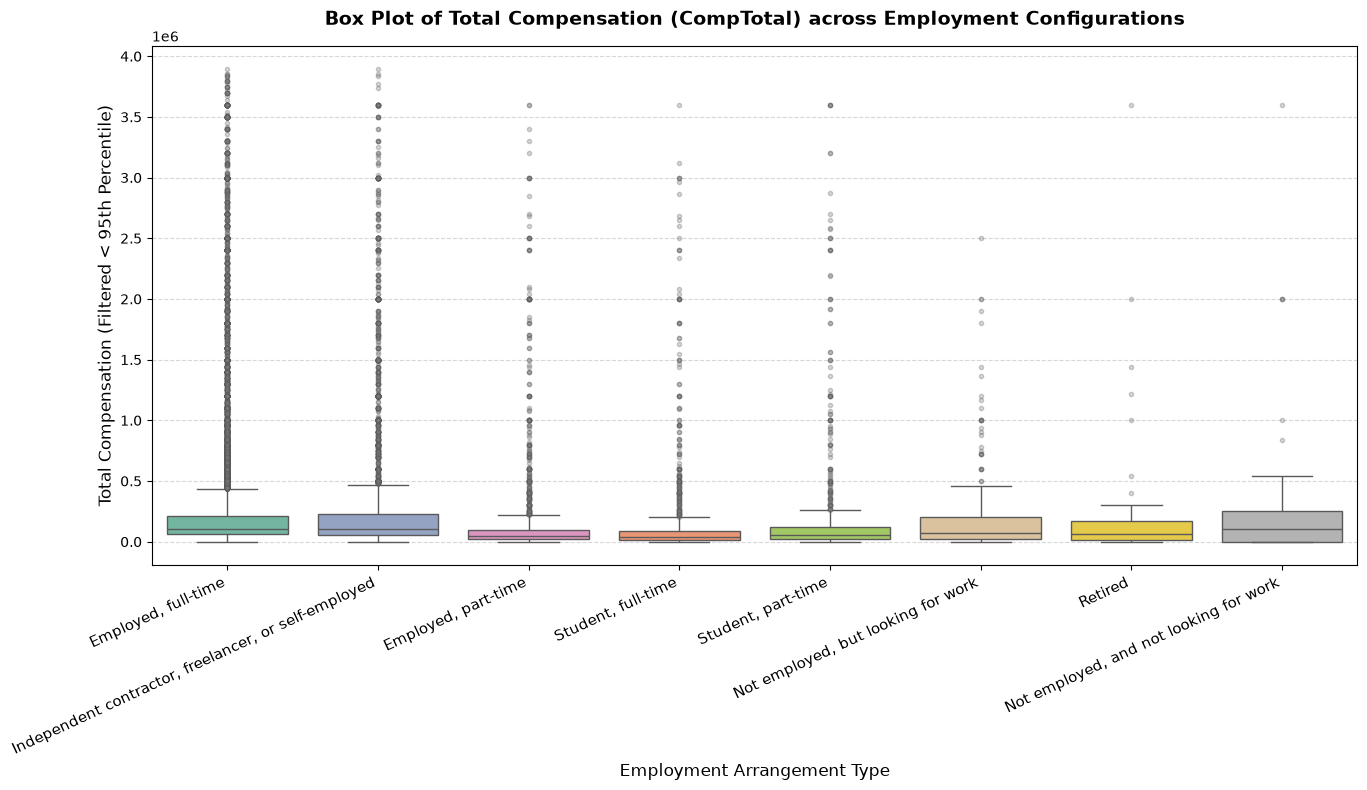

In [15]:
QUERY = """
SELECT CompTotal, Employment 
FROM main
WHERE CompTotal IS NOT NULL 
  AND Employment IS NOT NULL 
  AND Employment != ''
"""
df_raw = pd.read_sql_query(QUERY, conn)


df_raw['Employment'] = df_raw['Employment'].str.split(';')
df_exploded = df_raw.explode('Employment').copy()
df_exploded['Employment'] = df_exploded['Employment'].str.strip()


upper_limit = df_exploded['CompTotal'].quantile(0.95)
df_filtered = df_exploded[df_exploded['CompTotal'] <= upper_limit]


emp_order = df_filtered['Employment'].value_counts().index.tolist()


plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df_filtered,
    x='Employment',
    y='CompTotal',
    order=emp_order, 
    palette='Set2',
    hue='Employment',       
    legend=False,
    flierprops=dict(marker='o', markerfacecolor='grey', markersize=3, alpha=0.3)
)


plt.title('Box Plot of Total Compensation (CompTotal) across Employment Configurations', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Employment Arrangement Type', fontsize=12)
plt.ylabel('Total Compensation (Filtered < 95th Percentile)', fontsize=12)
plt.xticks(rotation=25, ha='right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()



**2. Box Plot of `YearsCodePro` by Job Satisfaction (`JobSatPoints_6`):**


Examine the distribution of professional coding years by job satisfaction levels.


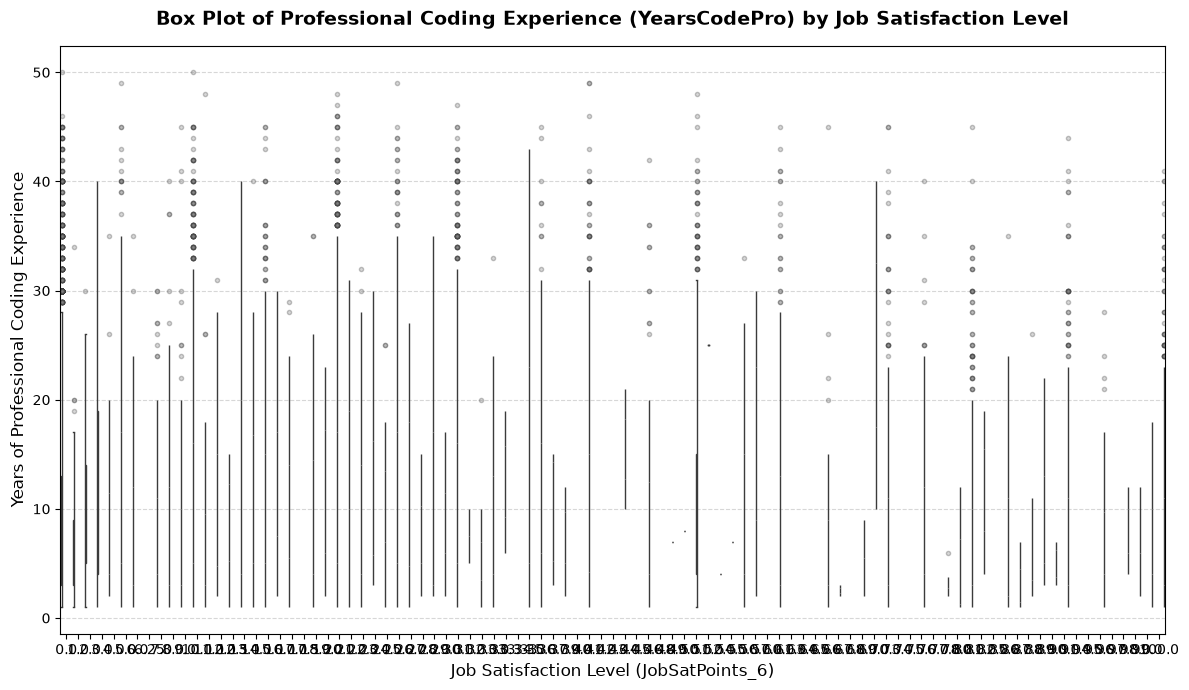

In [16]:
QUERY = """
SELECT YearsCodePro, JobSatPoints_6 
FROM main
WHERE YearsCodePro IS NOT NULL 
  AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(QUERY, conn)


df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce')
df = df.dropna(subset=['YearsCodePro'])


df = df[df['JobSatPoints_6'].astype(str).str.strip() != '']


satisfaction_order = sorted(df['JobSatPoints_6'].unique())
df['JobSatPoints_6'] = pd.Categorical(df['JobSatPoints_6'], categories=satisfaction_order, ordered=True)


plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='JobSatPoints_6',
    y='YearsCodePro',
    palette='coolwarm',
    hue='JobSatPoints_6', 
    legend=False,
    flierprops=dict(marker='o', markerfacecolor='grey', markersize=3, alpha=0.3)
)


plt.title('Box Plot of Professional Coding Experience (YearsCodePro) by Job Satisfaction Level', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Job Satisfaction Level (JobSatPoints_6)', fontsize=12)
plt.ylabel('Years of Professional Coding Experience', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()



### Final Step: Close the Database Connection


After completing the lab, close the connection to the SQLite database:


In [17]:
conn.close()

## Summary


In this lab, you used box plots to visualize various aspects of the dataset, focusing on:

- Visualize distributions of compensation and age.

- Explore relationships between compensation, job satisfaction, and professional coding experience.

- Analyze data composition across developer roles and countries.

- Compare compensation across employment types and satisfaction levels.

Box plots provided clear insights into the spread, outliers, and central tendencies of various features in the dataset.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
